In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# K Means Model
from sklearn.cluster import KMeans
# Data Preprocessing
from sklearn.preprocessing import StandardScaler, LabelEncoder
# Metrics
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv('Dataset/Mall_Customers.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
# sns.boxplot(df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']])

In [4]:
le = LabelEncoder()

In [5]:
df['GenderId'] = le.fit_transform(df['Gender'])

## Features

In [6]:
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'GenderId']
X = df[features]

## Feature Scaling

In [7]:
scaler = StandardScaler()
X_scale = scaler.fit_transform(X)

## Elbow Method

In [8]:
import warnings
warnings.filterwarnings("ignore")

In [9]:
k_range = range(1, 21)
error_rate = []
for i in k_range:
    kmeans = KMeans(n_clusters=i)
    kmeans.fit_predict(X_scale)
    error_rate.append(kmeans.inertia_)

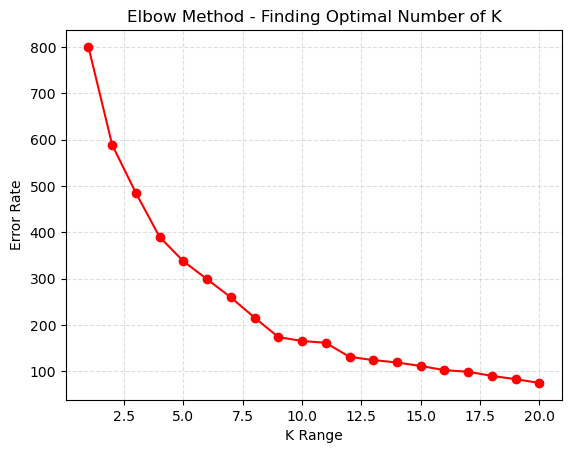

In [10]:
plt.plot(k_range, error_rate, marker='o', color='red')
plt.grid(linestyle='--', alpha=0.4)
plt.xlabel('K Range')
plt.ylabel('Error Rate')
plt.title('Elbow Method - Finding Optimal Number of K')
plt.show()

## Model Implementation

In [11]:
k = 5

model = KMeans(n_clusters=k)
clusters = model.fit_predict(X_scale)
clusters

array([4, 4, 0, 4, 4, 4, 0, 4, 2, 4, 2, 4, 0, 4, 2, 4, 0, 4, 2, 4, 2, 4,
       0, 4, 0, 4, 0, 4, 0, 4, 2, 4, 2, 4, 0, 4, 0, 4, 0, 4, 0, 4, 2, 4,
       0, 4, 0, 4, 0, 0, 0, 4, 3, 2, 0, 2, 0, 2, 3, 2, 2, 4, 0, 0, 2, 4,
       0, 0, 4, 3, 2, 0, 0, 0, 2, 1, 0, 2, 3, 0, 2, 1, 2, 0, 3, 2, 0, 3,
       3, 0, 0, 1, 2, 0, 3, 1, 0, 3, 2, 1, 3, 0, 2, 1, 2, 3, 0, 2, 2, 2,
       2, 3, 3, 1, 3, 3, 0, 0, 0, 0, 1, 3, 3, 1, 3, 3, 2, 1, 2, 1, 2, 1,
       3, 3, 1, 3, 0, 1, 1, 3, 0, 1, 3, 3, 1, 1, 2, 3, 3, 1, 2, 1, 0, 3,
       0, 3, 2, 3, 2, 3, 0, 3, 1, 3, 2, 3, 2, 3, 3, 1, 2, 1, 2, 1, 0, 3,
       2, 1, 2, 1, 3, 3, 2, 3, 3, 1, 0, 1, 3, 3, 3, 3, 1, 3, 3, 3, 3, 1,
       1, 1], dtype=int32)

In [12]:
X['clusters'] = clusters

In [13]:
ss = silhouette_score(X_scale, labels=clusters)
ss

0.29198437680362893

In [14]:
# 'Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'GenderId'

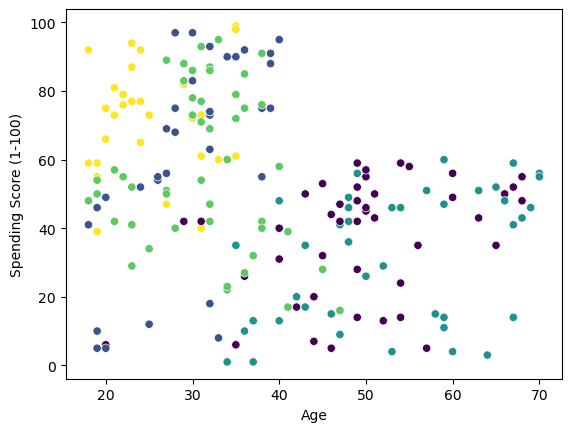

In [34]:
sns.scatterplot(data=X, x='Age', y='Spending Score (1-100)', c=clusters)
plt.show()

In [16]:
import plotly.express as px

In [17]:
px.scatter_3d(
    X,
    x='Age',
    y='Annual Income (k$)',
    z='Spending Score (1-100)',
    color=clusters
)

## Pair Plot

In [18]:
pair_plot = X

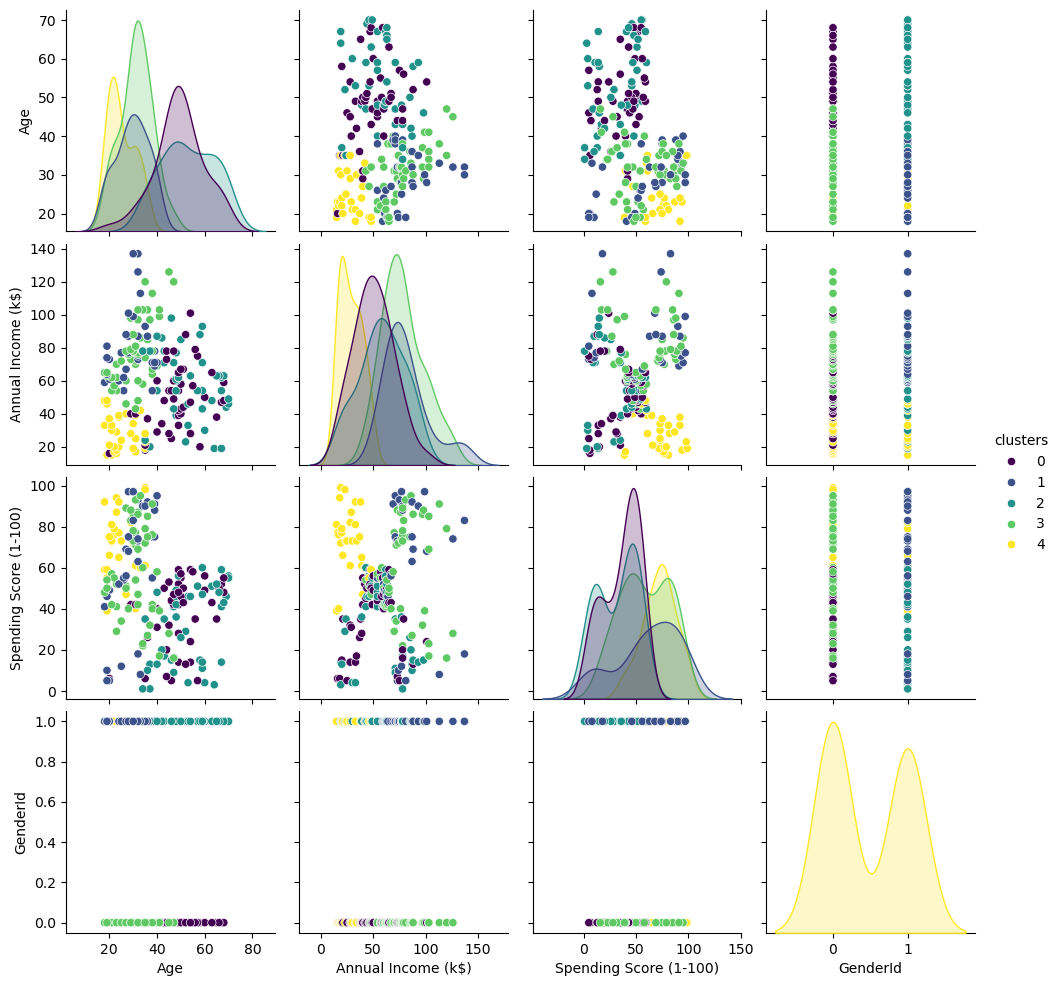

In [19]:
sns.pairplot(
    pair_plot,
    hue='clusters',
    palette='viridis'
)
plt.show()

# PCA (Principle Component Analysis)

In [20]:
from sklearn.decomposition import PCA

In [21]:
pca = PCA(n_components=len(features))

In [22]:
# Calculation of Co-Variance
pca_scale = pca.fit_transform(X_scale)

In [23]:
# Finding important data for axis
loadings = pd.DataFrame(
    pca.components_,
    index=features,
    columns = [f'PC{i+1}' for i in range(len(features))]
)
loadings

,PC1,PC2,PC3,PC4
Age,0.687900,-0.006082,-0.686920,0.234302
Annual Income (k$),-0.103690,0.765252,0.103211,0.626886
Spending Score (1-100),-0.122384,-0.643667,0.136573,0.743009
GenderId,0.707859,0.006721,0.706283,-0.007405


In [ ]:
'''
PC1 -> Value High -> Features -> X-axis
PC2 -> Value High -> Features -> Y-axis

X -> Age, Gender
Y -> Annual Income, Spending Score
'''

### Visualization PCA

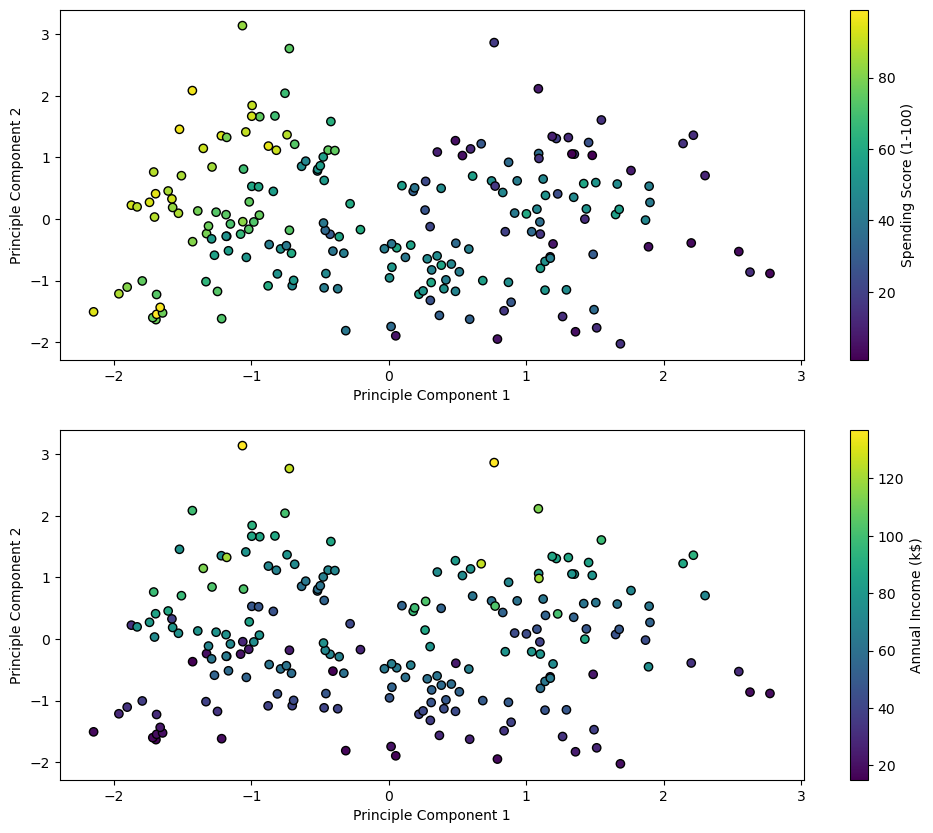

In [55]:
# plt.figure(figsize=(10, 4))
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

ax1 = axes[0]
color1 = 'Spending Score (1-100)'
scatter = ax1.scatter(pca_scale[:,0], pca_scale[:,1], c=df[color], edgecolor='#000')
cbar = fig.colorbar(scatter, ax=ax1)
cbar.set_label(color1)
ax1.set_xlabel('Principle Component 1')
ax1.set_ylabel('Principle Component 2')


ax2 = axes[1]
color2 = 'Annual Income (k$)'
scatter = ax2.scatter(pca_scale[:,0], pca_scale[:,1], c=df[color2], edgecolor='#000')
cbar = fig.colorbar(scatter, ax=ax2)
cbar.set_label(color2)
ax2.set_xlabel('Principle Component 1')
ax2.set_ylabel('Principle Component 2')

plt.savefig('pca.png')
plt.show()